#  The Problem

    Airbnb is a hospitality company that runs an online marketplace for renting and leasing short-term lodging, primarily homestays, or tourism experiences. The company does not own any of the real estate listings, nor does it host events; it acts as a broker, receiving commissions from each booking. 
    It is interested in developing a pricing service for its users that will compute a recommended price based on the features of a listing. You are approached by Airbnb to develop a model for predicting nightly prices of Airbnb listings based on state-of-art techniques from statistical machine learning.

#### Data Description:

    Id: Serial no.
    price: price per night
    host_is_superhost: T-True the host is  super-host, f-False the host is not a super-host ( A superhost is a a mark of quality, requiring various conditions to be met)
    host_total_listings_count:how many listings the host is responsible for in total.
    host_identity_verified: t- True, the host identity is verified, 
                            f-False, identity not verified (e.g. by verifying government ID, a phone number and an email address)
    latitude: geographical location of the place with respect to latitude.
    longitude: geographical location of the place with respect to longitute.
    property_type: type of property (e.g. apartment, room, boat, cabin, guesthouse, hostel etc.)
    room_type: Type of room (e.g. sharing, private, entire house etc)
    accommodates: total no. of people the property can accommodate.
    bathrooms: no. of bathrooms.
    bedrooms: no. of bedrooms
    beds:no. of beds. 
    security_deposit: security deposit amount.
    cleaning_fee: fee charged for cleaning.
    extra_people: extra people charges.
    minimum_nights: duration of stay minimum nights. 
    maximum_nights: duration of stay maximum nights.
    number_of_reviews: total no. of reviews.
    (review_scores_rating, review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication,review_scores_location, review_scores_value)-Review ratings for each category (accuracy, cleanliness, check-in, communication, location, value and overall total)
    instant_bookable: t-True booking can be done instantly,
                      f-False booking cannot be done instantly.
    is_business_travel_ready: is it ready for stay related to business purpose.
    cancellation_policy: cancellation policy of the host (eg. strict, moderate, flexible)
    reviews_per_month: monthly review scores

### Importing Libraries

In [166]:
import pandas as pd     
import numpy as np

import matplotlib.pyplot as plt  
%matplotlib inline
import seaborn as sns           
colour=sns.color_palette()

import math
from sklearn.preprocessing import MinMaxScaler
from sklearn import metrics
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_predict

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV

In [3]:
air_df = pd.read_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/DataTales/DT02-airbnb/train.csv')

In [4]:
print(air_df.shape)  

(1000, 30)


    What do you understand from the above tuple?
---

    It simply means there are 1000 records and 30 features in the dataset

In [6]:
pd.set_option('display.max_column',50)
air_df.head()

,Id,price,host_is_superhost,host_total_listings_count,host_identity_verified,latitude,longitude,property_type,room_type,accommodates,bathrooms,bedrooms,beds,security_deposit,cleaning_fee,extra_people,minimum_nights,maximum_nights,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,is_business_travel_ready,cancellation_policy,reviews_per_month
0,0,150,f,22.0,t,-33.846469,151.205171,Apartment,Entire home/apt,2,1.0,1,1.0,500.0,330.0,0,7,1125,1,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f,f,strict,0.53
1,1,66,f,1.0,t,-33.895736,151.173529,Apartment,Private room,2,1.5,1,1.0,NaN,NaN,0,21,30,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,f,flexible,NaN
2,2,325,t,1.0,t,-33.879322,151.222408,House,Entire home/apt,4,2.0,2,2.0,500.0,180.0,0,3,90,21,99.0,10.0,10.0,10.0,10.0,10.0,9.0,f,f,moderate,2.38
3,3,145,f,1.0,f,-33.856874,151.149600,House,Entire home/apt,6,1.5,3,4.0,0.0,80.0,0,4,1125,3,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f,f,flexible,1.96
4,4,200,f,6.0,t,-33.907150,151.178552,House,Entire home/apt,4,1.0,2,2.0,350.0,85.0,50,2,30,22,97.0,10.0,10.0,10.0,10.0,10.0,10.0,f,f,moderate,2.73


In [7]:
air_df.info()  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 30 columns):
Id                             1000 non-null int64
price                          1000 non-null int64
host_is_superhost              998 non-null object
host_total_listings_count      998 non-null float64
host_identity_verified         998 non-null object
latitude                       1000 non-null float64
longitude                      1000 non-null float64
property_type                  1000 non-null object
room_type                      1000 non-null object
accommodates                   1000 non-null int64
bathrooms                      997 non-null float64
bedrooms                       1000 non-null int64
beds                           998 non-null float64
security_deposit               574 non-null float64
cleaning_fee                   693 non-null float64
extra_people                   1000 non-null int64
minimum_nights                 1000 non-null int64
maximum_nights  

    From the above information we notice:
        1. The dataset has float, int and object type data
        2. Object type features only imply True/False
        3. some features have many missing values(nulls)

In [8]:
air_df.describe()

,Id,price,host_total_listings_count,latitude,longitude,accommodates,bathrooms,bedrooms,beds,security_deposit,cleaning_fee,extra_people,minimum_nights,maximum_nights,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month
count,1000.000000,1000.000000,998.000000,1000.000000,1000.000000,1000.000000,997.000000,1000.000000,998.000000,574.000000,693.000000,1000.00000,1000.000000,1000.000000,1000.000000,660.000000,658.000000,658.000000,656.000000,657.000000,656.000000,656.000000,689.000000
mean,499.500000,145.521000,7.044088,-33.866773,151.205647,2.988000,1.255266,1.406000,1.748497,395.393728,75.176046,10.85600,3.807000,693.481000,9.592000,93.322727,9.537994,9.235562,9.730183,9.732116,9.637195,9.399390,1.203745
std,288.819436,91.428523,27.234486,0.068062,0.080778,1.681869,0.488096,0.797371,1.122342,466.069393,67.303734,21.09688,6.098274,534.775022,21.134526,10.021393,0.942446,1.237718,0.800040,0.783648,0.732717,1.010902,1.466470
min,0.000000,18.000000,1.000000,-34.092546,150.651014,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,1.000000,1.000000,0.000000,20.000000,2.000000,2.000000,2.000000,2.000000,6.000000,2.000000,0.020000
25%,249.750000,75.000000,1.000000,-33.899661,151.182542,2.000000,1.000000,1.000000,1.000000,150.000000,30.000000,0.00000,1.000000,30.000000,0.000000,90.000000,9.000000,9.000000,10.000000,10.000000,9.000000,9.000000,0.190000
50%,499.500000,120.000000,1.000000,-33.884990,151.217358,2.000000,1.000000,1.000000,1.000000,300.000000,60.000000,0.00000,2.000000,1125.000000,2.000000,97.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,0.640000
75%,749.250000,195.750000,2.000000,-33.843008,151.261443,4.000000,1.500000,2.000000,2.000000,500.000000,100.000000,20.00000,4.000000,1125.000000,7.000000,100.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,1.680000
max,999.000000,449.000000,205.000000,-33.401800,151.338687,16.000000,4.000000,5.000000,9.000000,6000.000000,500.000000,250.00000,90.000000,3000.000000,194.000000,100.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,9.130000


    Do you find anything out of ordinary from the above table?

    1. host_total_listings_count, bathrooms, beds, security_deposit, cleaning_fee and reviews on different category have missing values.
    2. variables like host_total_listing_counts, security_deposit, extra_people, maximum_nights and number_of_reviews seems to have outliers.

In [9]:
air_df.describe(include=object)

,host_is_superhost,host_identity_verified,property_type,room_type,instant_bookable,is_business_travel_ready,cancellation_policy
count,998,998,1000,1000,1000,1000,1000
unique,2,2,19,3,2,2,3
top,f,f,Apartment,Entire home/apt,f,f,strict
freq,905,509,651,589,693,976,392


    Most variables have only two levels(true/false),room_type and cancellation_policy have 3 levels and property_type has 19 levels.

## Data Pre-Processing

(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5, 20.5, 21.5,
        22.5, 23.5, 24.5, 25.5, 26.5, 27.5, 28.5, 29.5]),
 <a list of 30 Text xticklabel objects>)

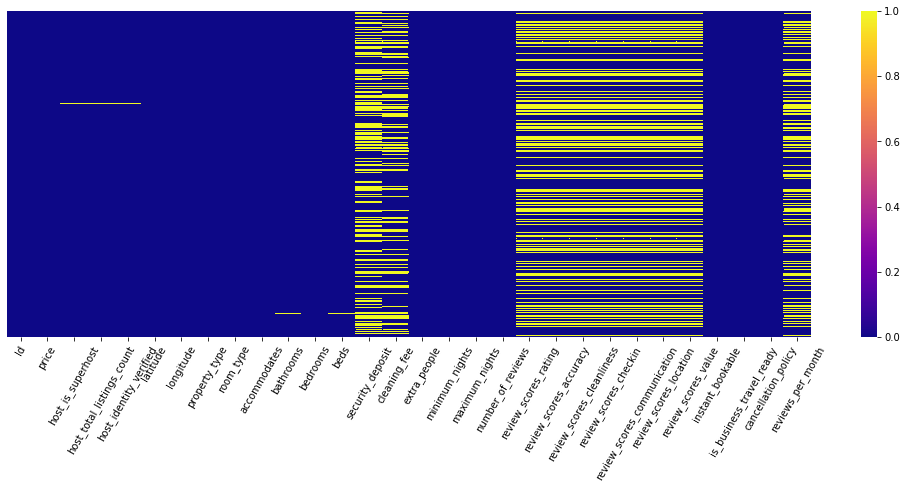

In [10]:
plt.figure(figsize=(18,6))
sns.heatmap(air_df.isnull(),yticklabels=False, xticklabels=air_df.columns, cmap='plasma') 
plt.xticks(rotation=60)

    Can you help interpret the above pallette?
---

    It is a representation of null and non-null values in the dataset. Yellow represents a null and blue - non-null

In [11]:
air_df.isnull().sum()

Id                               0
price                            0
host_is_superhost                2
host_total_listings_count        2
host_identity_verified           2
latitude                         0
longitude                        0
property_type                    0
room_type                        0
accommodates                     0
bathrooms                        3
bedrooms                         0
beds                             2
security_deposit               426
cleaning_fee                   307
extra_people                     0
minimum_nights                   0
maximum_nights                   0
number_of_reviews                0
review_scores_rating           340
review_scores_accuracy         342
review_scores_cleanliness      342
review_scores_checkin          344
review_scores_communication    343
review_scores_location         344
review_scores_value            344
instant_bookable                 0
is_business_travel_ready         0
cancellation_policy 

    There are null values in different types of variables, can you think of any strategy to deal with them?

    Dealing with null values can often be straight forward, given we have the domain expertise. However, there are some most commonly used approaches based on the type of variable
    
    Variable Type                        Strategy
     Continous                           Impute(mean, median, mode, z-score avg), remove
     Object/Categorical                  Impute(mode, based on other fields), remove
     
     There surely are other ways and not everyway fits in every scenario

In [12]:
col_null=[]
percentage=[]
counts=[]
for col in air_df.columns:
    if air_df[col].isnull().sum()!=0:
        null=air_df[col].isnull().sum()
        percent=round((air_df[col].isnull().sum()/air_df[col].isnull().count())*100,2)
        percentage.append(percent)
        col_null.append(col)
        counts.append(null)

In [13]:
null_summary=pd.DataFrame({'columns': col_null, 'null_values': counts, 'percentage_null_values':percentage })
null_summary.sort_values(by='null_values', ascending=False)

,columns,null_values,percentage_null_values
5,security_deposit,426,42.6
10,review_scores_checkin,344,34.4
12,review_scores_location,344,34.4
13,review_scores_value,344,34.4
11,review_scores_communication,343,34.3
8,review_scores_accuracy,342,34.2
9,review_scores_cleanliness,342,34.2
7,review_scores_rating,340,34.0
14,reviews_per_month,311,31.1
6,cleaning_fee,307,30.7


    Till now we have not seen the exact number of nulls. Now that we see it, why is it important to note the null values and respective percentages in each column?
---

    Some times there might be very low number of nulls and hence removing those rows is a good idea if the column with null doesn't contribute much to our target. We look at percentages to understand how feasable any of our strategies might work. For instance if there are 50% null values, removing all of them means removing 50% data so removal is not an option.

In [14]:
#imputing missing values for continuous variables
for num in air_df.select_dtypes(('float64', 'int64')):
    if air_df[num].isnull().sum()!=0:
        air_df[num]=air_df[num].fillna(air_df[num].mean())

In [15]:
#imputing the missing value of a categorical variables with most common entry
for col in air_df.select_dtypes('object'):
    air_df[col]=air_df[col].fillna(air_df[col].value_counts().index[0])

In some cases, the values of the variables fall in the extreme range, which will impact the model fitting
 in an undesirable way. These values are called outliers that fall ouside the range of (Q1-1.5 * IQR) and (Q3+1.5 * IQR)

IQR- Inter-quartile range,
Q1- first quartile 
Q3-third quartile

sometimes  these values are random, but sometimes it is not random it adds certain information to the data. In this cases we cannot drop these outliers. We term them as business outliers.

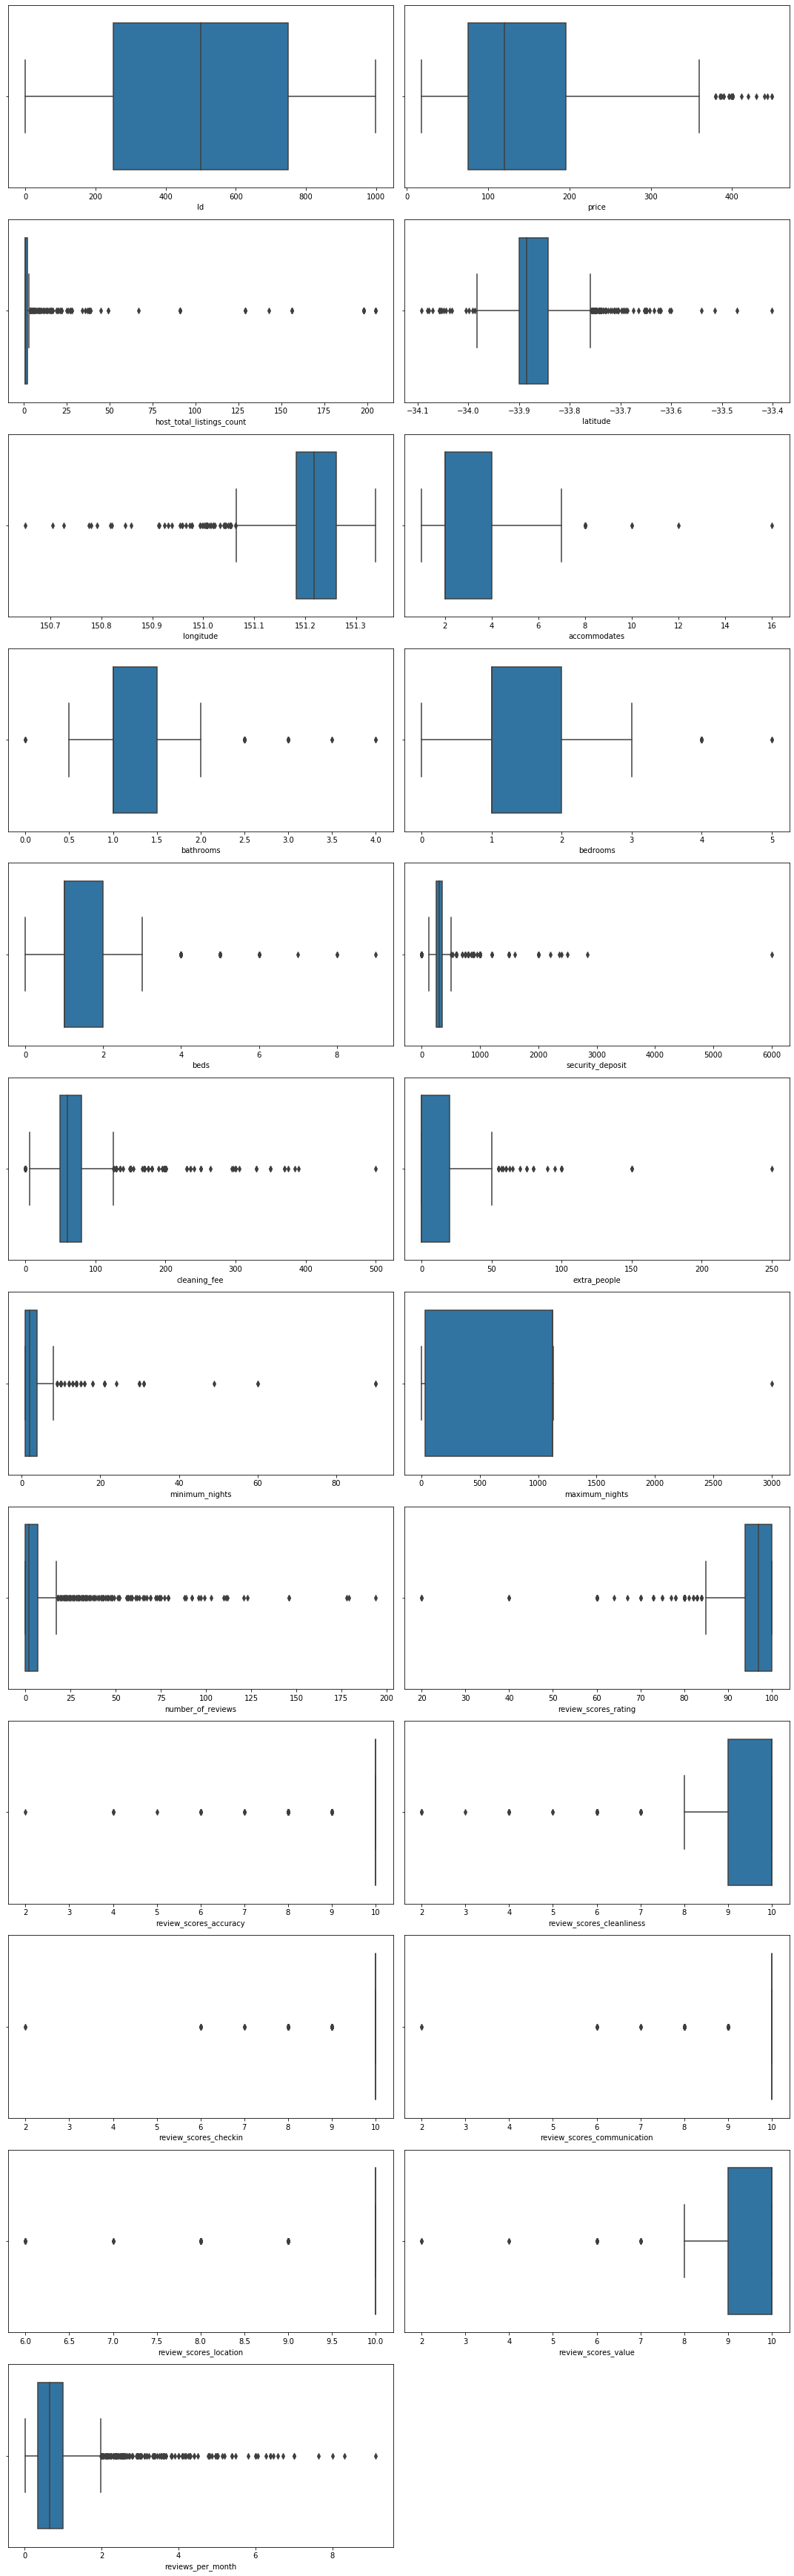

In [138]:
plt.figure(figsize=(15,60))
n=1
for column in air_df.select_dtypes(('int64', 'float64')):
    plt.subplot(15,2,n)
    sns.boxplot(x=air_df[column])
    plt.tight_layout()
    n=n+1
plt.show()

    Above is the ourliers when only 1.5 iqr is considered, let's consider 3 IQR.

In [16]:
air_df['accommodates'].quantile(0.25)

2.0

In [33]:
dict_outliers = dict()
for column in air_df.select_dtypes(('int64', 'float64')):
    q1 = air_df[column].quantile(0.25)
    q3 = air_df[column].quantile(0.75)
    iqr = q3 - q1
    iqr_3 = 3*iqr
    lower_limit = q1 - iqr_3
    upper_limit = q3 + iqr_3
    dict_outliers[column] = len(air_df[(air_df[column]<lower_limit) | (air_df[column]>upper_limit)][column])

In [34]:
dict_outliers

{'Id': 0,
 'price': 0,
 'host_total_listings_count': 106,
 'latitude': 22,
 'longitude': 15,
 'accommodates': 2,
 'bathrooms': 4,
 'bedrooms': 0,
 'beds': 11,
 'security_deposit': 61,
 'cleaning_fee': 53,
 'extra_people': 12,
 'minimum_nights': 38,
 'maximum_nights': 0,
 'number_of_reviews': 106,
 'review_scores_rating': 24,
 'review_scores_accuracy': 65,
 'review_scores_cleanliness': 13,
 'review_scores_checkin': 43,
 'review_scores_communication': 45,
 'review_scores_location': 52,
 'review_scores_value': 5,
 'reviews_per_month': 49}

    The highest outlier percent any column now has is less than 11%. These values if left alone will make most impact on our predictions. It is not always necessary to modify the inputs to reduce the effect of outliers, sometimes we can even choose metrics that do it. In our data, we know for a fact all outliers are positive integers so to reduce the effect of error we can consider minkowski distance. Instead of raising the error term to square, minkowski distance raises it to some number between 1 and 2.
    For example if our error is 10, squaring it becomes 100 while raising it to 1.5 will be 31.6

Let's convert all the object variables into categorical variables 

In [36]:
for col in air_df.select_dtypes('object'):
    air_df[col]=air_df[col].astype('category')
print(air_df.dtypes) 

Id                                int64
price                             int64
host_is_superhost              category
host_total_listings_count       float64
host_identity_verified         category
latitude                        float64
longitude                       float64
property_type                  category
room_type                      category
accommodates                      int64
bathrooms                       float64
bedrooms                          int64
beds                            float64
security_deposit                float64
cleaning_fee                    float64
extra_people                      int64
minimum_nights                    int64
maximum_nights                    int64
number_of_reviews                 int64
review_scores_rating            float64
review_scores_accuracy          float64
review_scores_cleanliness       float64
review_scores_checkin           float64
review_scores_communication     float64
review_scores_location          float64


    Can you identify the differences of object and category types? also where each of those work best?

    We can also consider converting the following variables to categorical
    'accommodates','bedrooms','bathrooms','beds','extra_people', 'minimum_nights','maximum_nights', 'number_of_reviews'

In [53]:
air_df[['accommodates','bedrooms','bathrooms','beds','extra_people', 'minimum_nights','maximum_nights', 'number_of_reviews']] = air_df[['accommodates','bedrooms','bathrooms','beds','extra_people', 'minimum_nights','maximum_nights', 'number_of_reviews']].astype('category')


In [54]:
air_df.head()


,Id,price,host_is_superhost,host_total_listings_count,host_identity_verified,latitude,longitude,property_type,room_type,accommodates,bathrooms,bedrooms,beds,security_deposit,cleaning_fee,extra_people,minimum_nights,maximum_nights,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,is_business_travel_ready,cancellation_policy,reviews_per_month
0,0,150,f,22.0,t,-33.846469,151.205171,Apartment,Entire home/apt,2,1.0,1,1.0,500.000000,330.000000,0,7,1125,1,100.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.00000,f,f,strict,0.530000
1,1,66,f,1.0,t,-33.895736,151.173529,Apartment,Private room,2,1.5,1,1.0,395.393728,75.176046,0,21,30,0,93.322727,9.537994,9.235562,9.730183,9.732116,9.637195,9.39939,f,f,flexible,1.203745
2,2,325,t,1.0,t,-33.879322,151.222408,House,Entire home/apt,4,2.0,2,2.0,500.000000,180.000000,0,3,90,21,99.000000,10.000000,10.000000,10.000000,10.000000,10.000000,9.00000,f,f,moderate,2.380000
3,3,145,f,1.0,f,-33.856874,151.149600,House,Entire home/apt,6,1.5,3,4.0,0.000000,80.000000,0,4,1125,3,100.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.00000,f,f,flexible,1.960000
4,4,200,f,6.0,t,-33.907150,151.178552,House,Entire home/apt,4,1.0,2,2.0,350.000000,85.000000,50,2,30,22,97.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.00000,f,f,moderate,2.730000


In [56]:
air_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 30 columns):
Id                             1000 non-null int64
price                          1000 non-null int64
host_is_superhost              1000 non-null category
host_total_listings_count      1000 non-null float64
host_identity_verified         1000 non-null category
latitude                       1000 non-null float64
longitude                      1000 non-null float64
property_type                  1000 non-null category
room_type                      1000 non-null category
accommodates                   1000 non-null category
bathrooms                      1000 non-null category
bedrooms                       1000 non-null category
beds                           1000 non-null category
security_deposit               1000 non-null float64
cleaning_fee                   1000 non-null float64
extra_people                   1000 non-null category
minimum_nights                 1000 non-n

## Exploratory Data Analysis

Text(0, 0.5, 'Frequency')

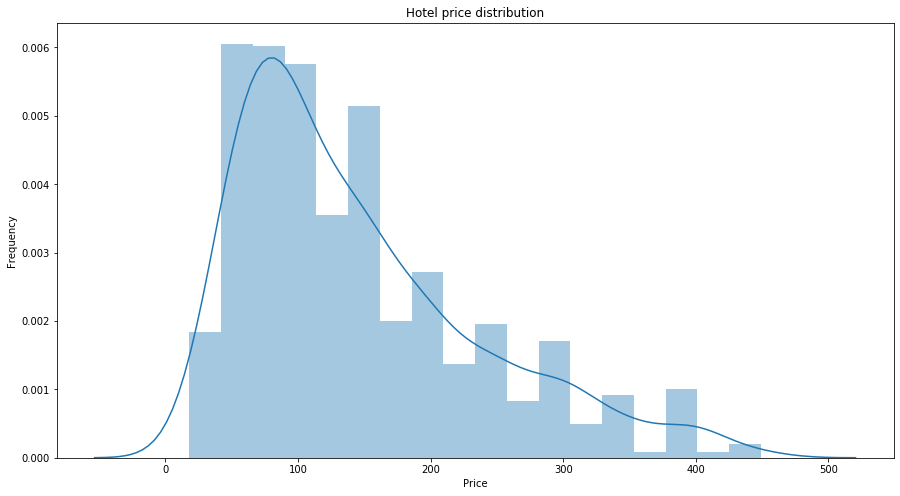

In [37]:
plt.figure(figsize=(15,8))
sns.distplot(air_df['price'])
plt.title('Hotel price distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')

    From the above graph we can see that the per night prices are right skewed, this means that the mean will be higher than the mode. night prices of most hosts are between 50 to 200.

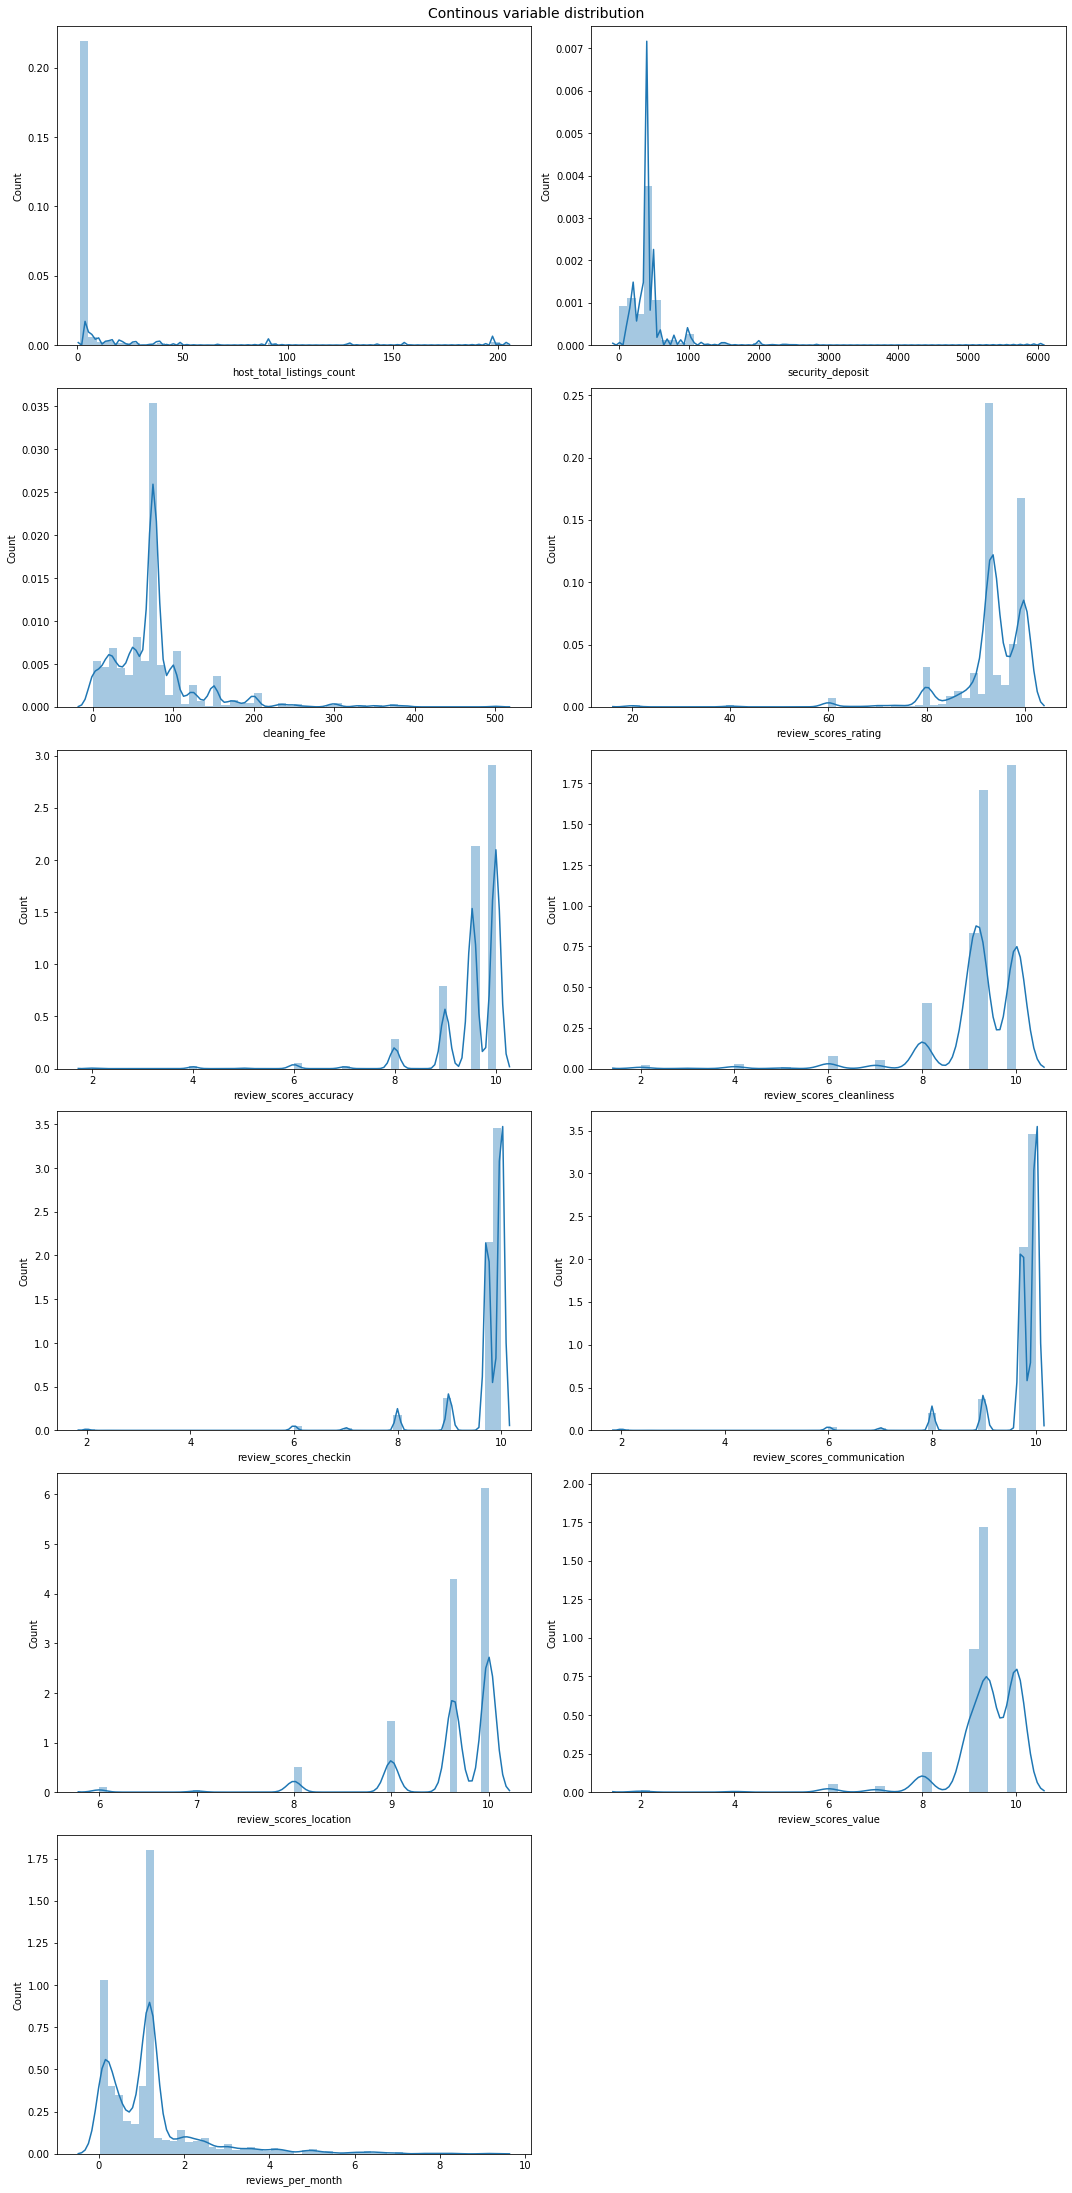

In [61]:
plt.figure(figsize=(15,60))
n=1
columns = air_df.select_dtypes(('float64', 'int64')).drop(['Id','latitude','longitude'],axis=1)
for col in columns:
    if col!='price':
        plt.subplot(12,2,n)
        sns.distplot(air_df[col])
        plt.ylabel('Count')
        plt.tight_layout()
        n=n+1

plt.suptitle('Continous variable distribution',fontsize=14,y=1.002)
plt.show()

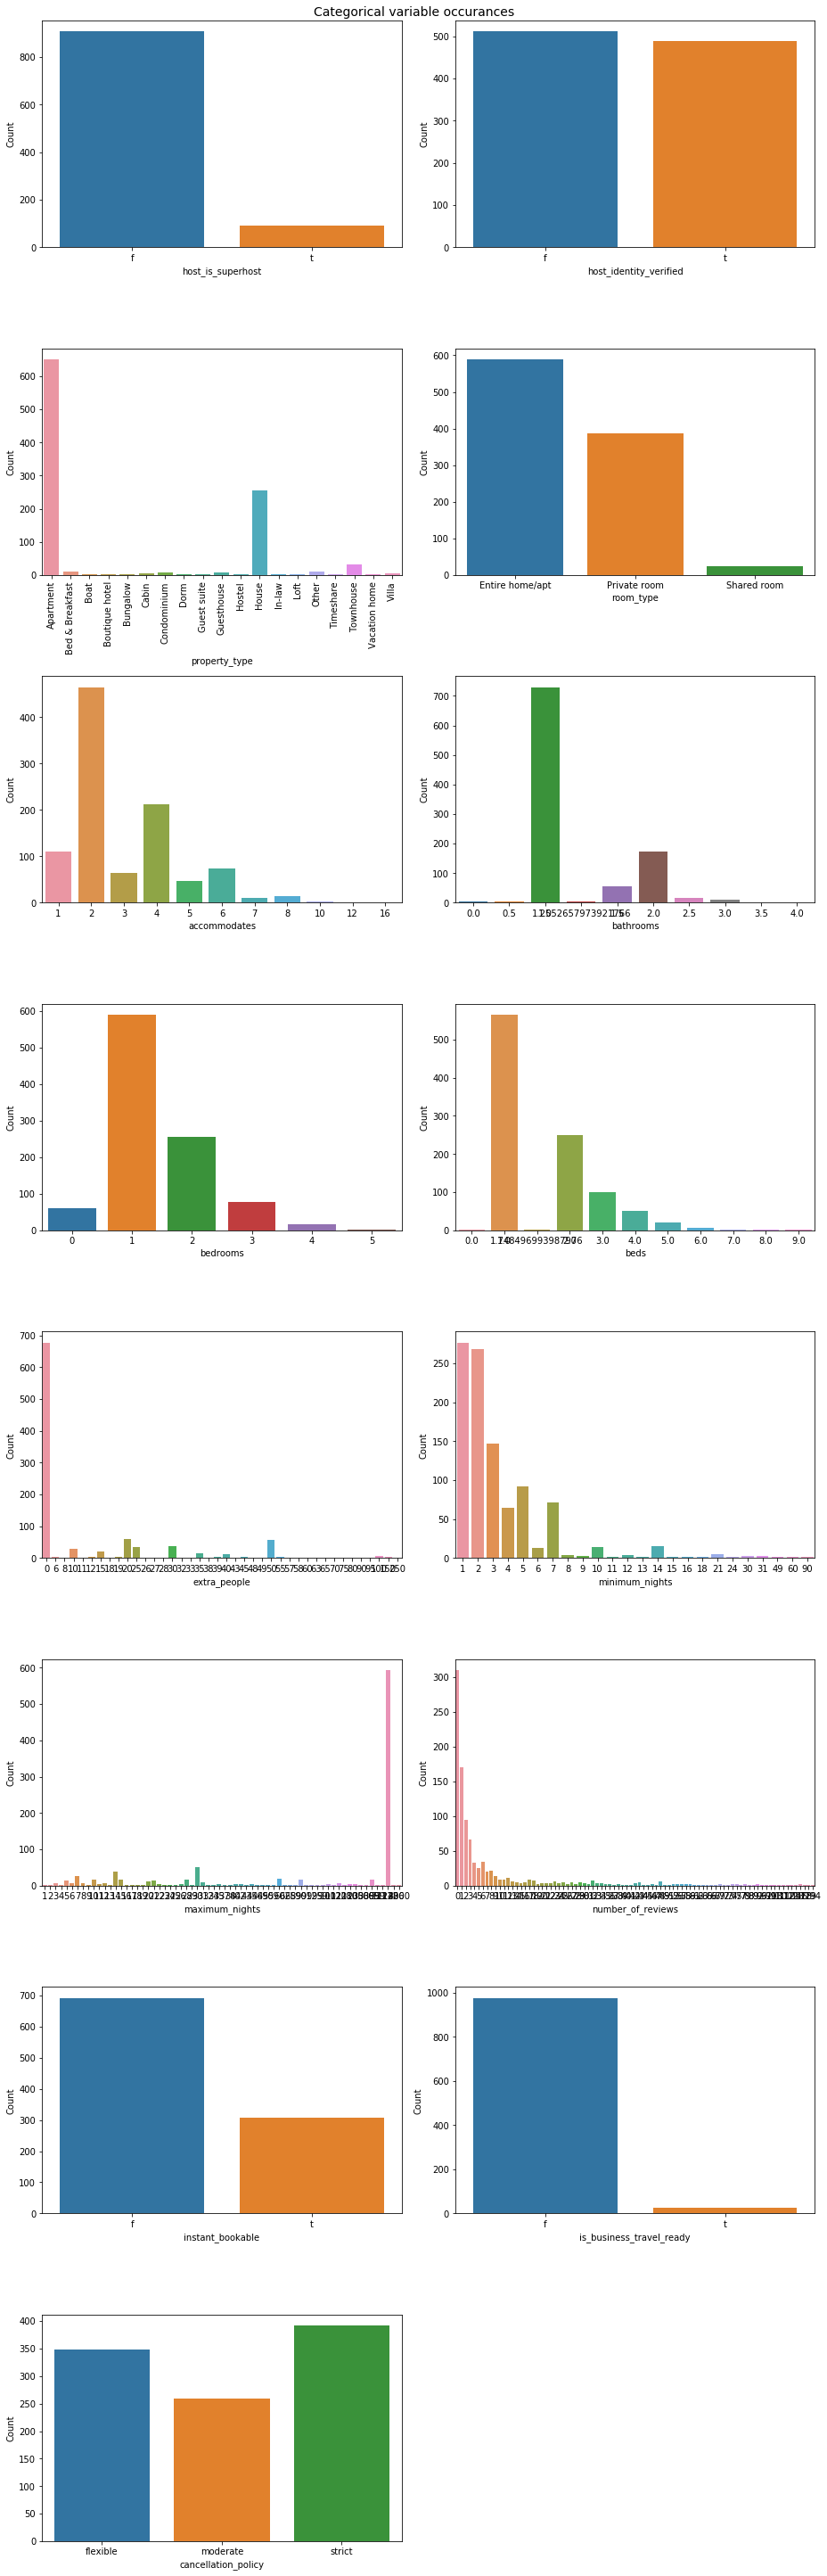

In [67]:
plt.figure(figsize=(13,40))
n=1
for col in air_df.select_dtypes('category'):
    plt.subplot(8,2,n)
    sns.countplot(x=col, data=air_df)
    plt.ylabel('Count')
    plt.tight_layout()
    n=n+1
    if col=='property_type':                   
         plt.xticks(rotation=90)

plt.suptitle('Categorical variable occurances',fontsize=14,y=1.002)
plt.show()

    host_is_superhost: We can see that more than 90% of places are not a superhost.

    host_identity_verified: around 500 places identity is not verified. i.e only 50% of places have their identity verified.

    property_type: A large no. of places are apartments and houses. 'room_type' and 'property_type' are interrelated, we notice that a large no of apartment and houses are given on rent or leasing entirely, only is some properties we see the provision of private rooms and even less no. of shared room provisions. This can be because most hosts prefer to have and give some privacy. 

    Very less no. of places can be instantly booked, and even lesser no. of places are ready for business travelers. Most of the host have a strict cancellation policy while considerable no. of hosts are flexible with it.

#### Part :2 Bi-variate Analysis

    Graphical representation of the correlation between variables using heatmap

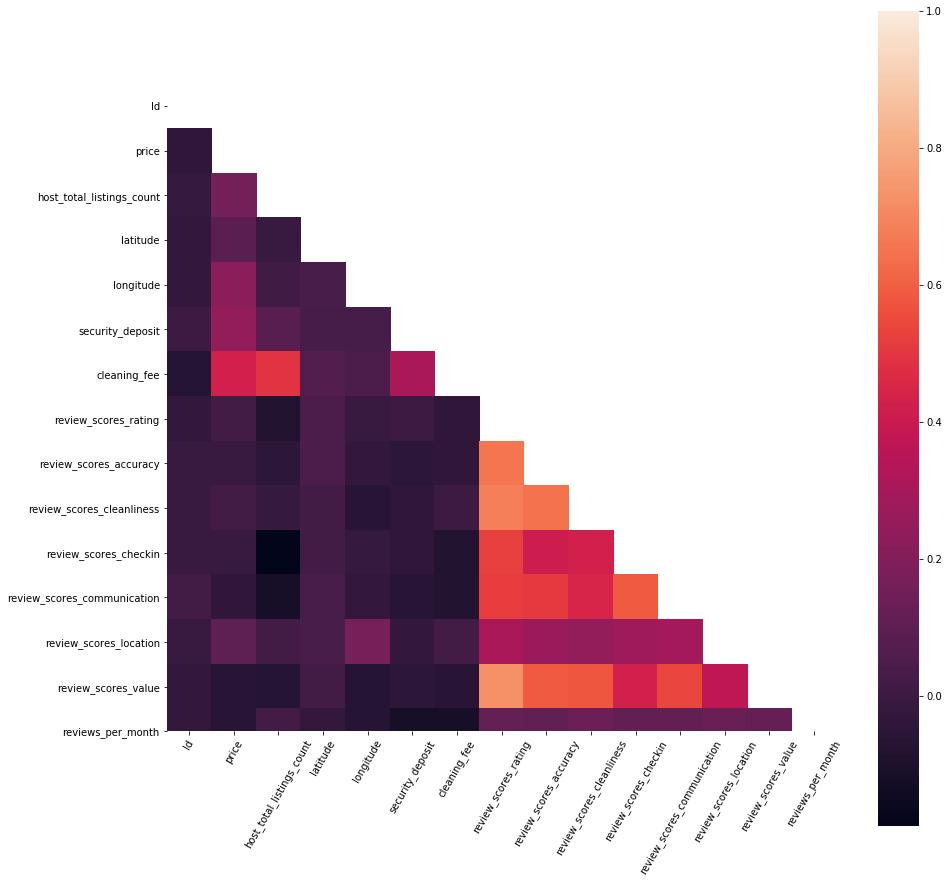

In [73]:
plt.figure(figsize=(15,15))
corr=round(air_df.corr(),2)
mask = np.triu(np.ones_like(corr, dtype=np.bool))
sns.heatmap(corr,mask=mask, square=True, annot=False)
plt.xticks(rotation=60)
plt.show()

    Variables like accommodates, bedrooms, beds, cleaning_fee, bathrooms, security_deposite and longitude shows good correlation with the price.
    We also see a lot of correlation between accommodates, bathroom, bedrooms and beds

    longitude: correlation with price signifies that price are also dependent on location.

In [74]:
num_col=[]
correlation=[]
for x in air_df.select_dtypes(('float64', 'int64')):
    if x!='Id':
        if x!='price':
            corr=round(air_df['price'].corr(air_df[x]),2)
            correlation.append(corr)
            num_col.append(x)
    

In [75]:
corr_table=pd.DataFrame({'columns': num_col, 'correlation':correlation})
corr_table.sort_values(by='correlation', ascending=False)

,columns,correlation
4,cleaning_fee,0.43
3,security_deposit,0.25
2,longitude,0.23
0,host_total_listings_count,0.16
10,review_scores_location,0.10
1,latitude,0.09
5,review_scores_rating,0.02
7,review_scores_cleanliness,0.02
6,review_scores_accuracy,-0.01
8,review_scores_checkin,-0.01


    From the table we can see that variables hotel_total_listings_counts, extra_people, minimum_nights are only slightly correlated with the target variable 

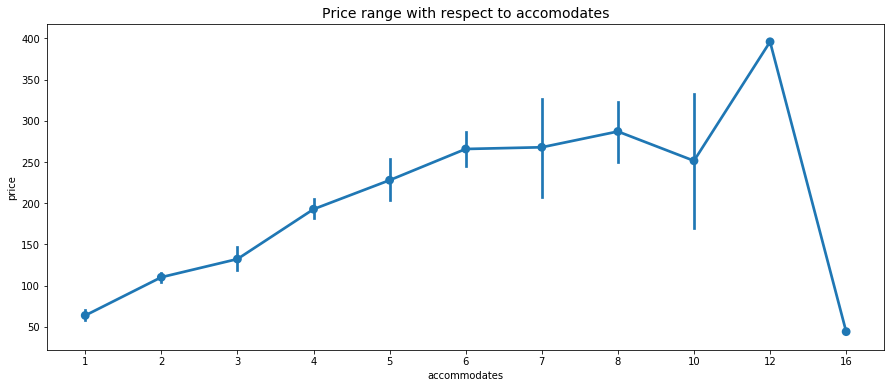

In [76]:
plt.figure(figsize=(15,6))
sns.pointplot(x='accommodates', y='price', data=air_df)
plt.title('Price range with respect to accomodates',fontsize=14)
plt.show()

     We see a gradual increase in price as the no. of accommodates increases, but there is dip in price when the accomodates are 10 and 16. lets check why is there a price such a steep drop for 16 accommodates

In [77]:
sixteen_acc=air_df[air_df['accommodates']==16]
sixteen_acc

,Id,price,host_is_superhost,host_total_listings_count,host_identity_verified,latitude,longitude,property_type,room_type,accommodates,bathrooms,bedrooms,beds,security_deposit,cleaning_fee,extra_people,minimum_nights,maximum_nights,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,is_business_travel_ready,cancellation_policy,reviews_per_month
429,429,44,f,3.0,f,-33.890913,151.23726,House,Shared room,16,3.0,1,8.0,395.393728,75.176046,0,7,1125,0,93.322727,9.537994,9.235562,9.730183,9.732116,9.637195,9.39939,f,f,flexible,1.203745


    16 accommodates:  it’s a house with a single bedroom, 3 bathrooms and 8 beds which is supposed to be shared hence there is fall in the price for 16 accommodates. Since there is only 1 record of this sort there is no saying this will actually help our model predict the prices better. However, that is an interesting observation

In [78]:
b_group=['bathrooms', 'bedrooms', 'beds']

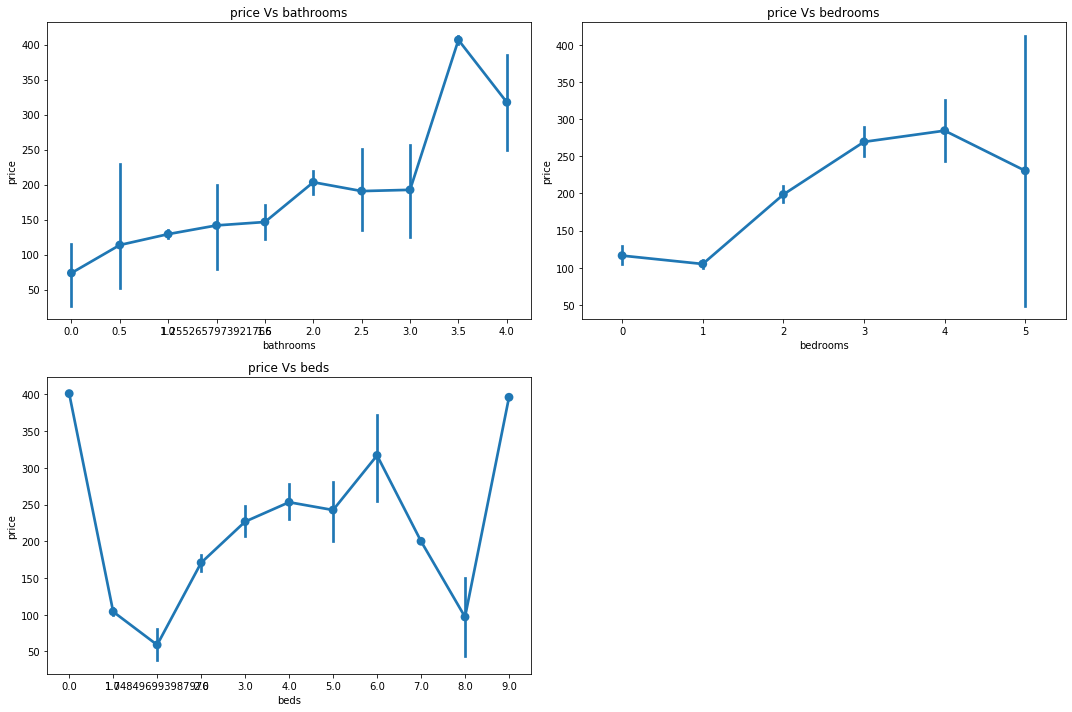

In [79]:
plt.figure(figsize=(15,10))
n=1
for var in b_group:
    plt.subplot(2,2,n)
    sns.pointplot(x=var, y='price', data=air_df)
    n=n+1
    plt.title('price Vs ' + var)
    plt.tight_layout()
plt.show()

    Price increases with increase in the no. of bedrooms and bathrooms. 

    Beds: price of bed increase gradually when from 1 bed to 6 beds, 7 and 8 beds price slows down. where as the price of 0 bed and 9 beds are quite high, can you think why?

    As per our data it is not very common to have shared dormitories with 9 beds and hence as the number of beds is at the highest the price took a hike. But the records for 8 beds belongs to shared rooms and hence a price dip

In [83]:
print('# records 8 beds: {}, 9 beds: {}'.format(len(air_df[air_df['beds']==8]),len(air_df[air_df['beds']==9])))

# records 8 beds: 2, 9 beds: 1


In [84]:
payments=['cleaning_fee', 'security_deposit']

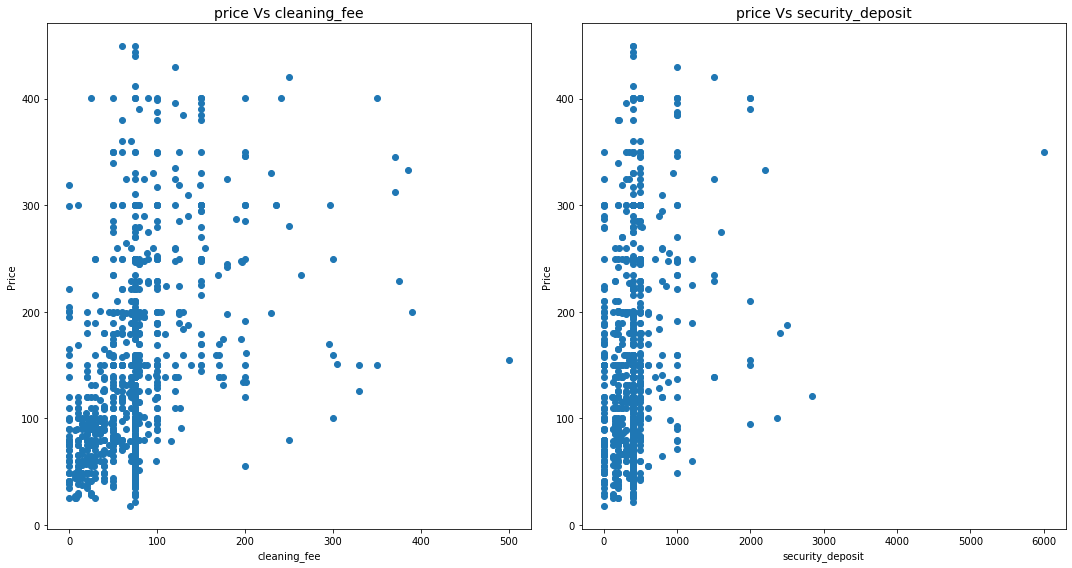

In [86]:
plt.figure(figsize=(15,8))
n=1
for pay in payments:
    plt.subplot(1,2,n)
    plt.title('price Vs ' + pay,fontsize=14)
    plt.scatter(air_df[pay], air_df['price'])
    plt.xlabel(pay)
    plt.ylabel('Price')
    n=n+1
    plt.tight_layout()
plt.show()

    Cleaning Fee:  we notice that the most of hotel cleaning fee below 100 has night charges below 200.
    security deposit: We can see an outlier here with 6000 as security fee. we will remove this outlier feature engineering section.

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:5: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  """


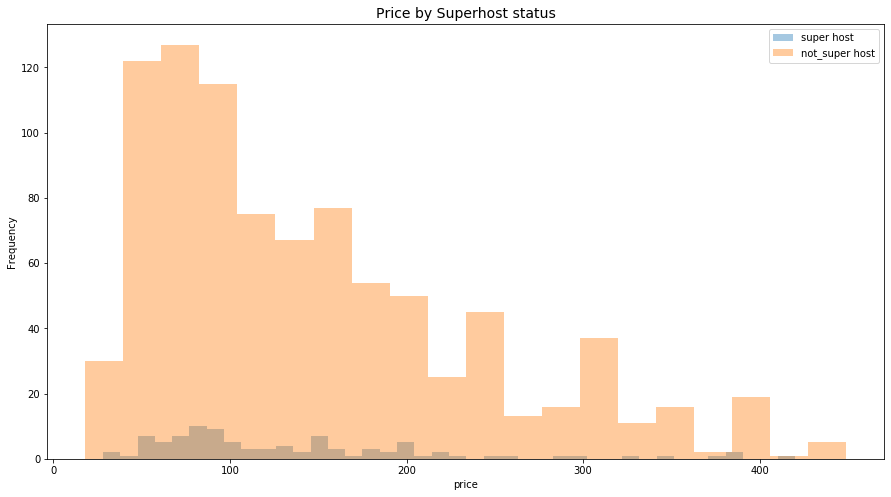

In [87]:
plt.figure(figsize=(15,8))
plt.title('Price by Superhost status',fontsize=14)
super_host=air_df[air_df['host_is_superhost']=='t']
no_super_host=air_df[air_df['host_is_superhost']=='f']
plt.subplot(1,1,1)
sns.distplot(super_host['price'], kde=False, bins=40, label='super host')
sns.distplot(no_super_host['price'], kde=False, bins=20, label='not_super host') 
plt.ylabel('Frequency')
plt.legend()
plt.show()


    We see that both super_host and nto_super_host have similar price distribution. i.e. the price for both super_host and not a super host are right skewed  

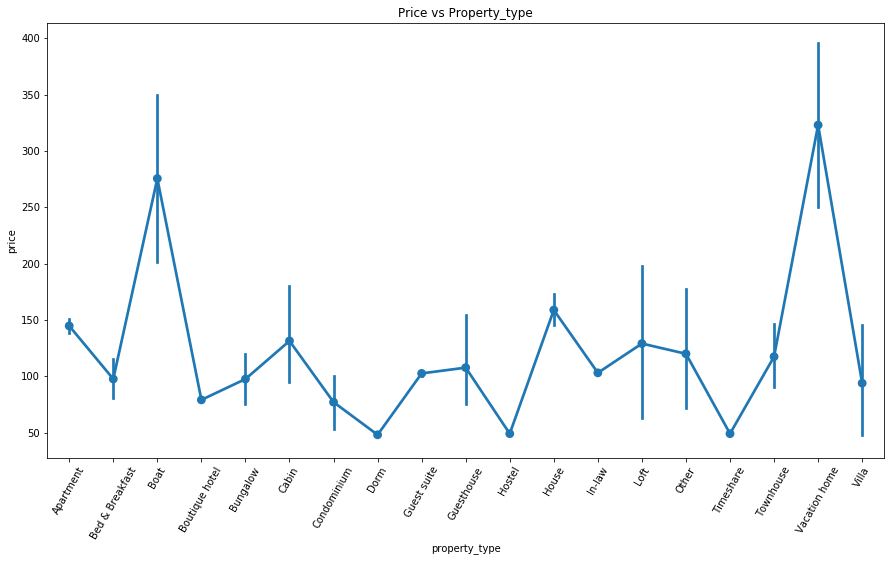

In [91]:
plt.figure(figsize=(15,8))
plt.title('Price vs Property_type')
chart=sns.pointplot(x='property_type', y='price', data=air_df)
chart.set_xticklabels(chart.get_xticklabels(), rotation=60)
plt.show()

    We can see the properties like boat and vacation homes have expensive stays, where as hostel and timeshare have very economical stays

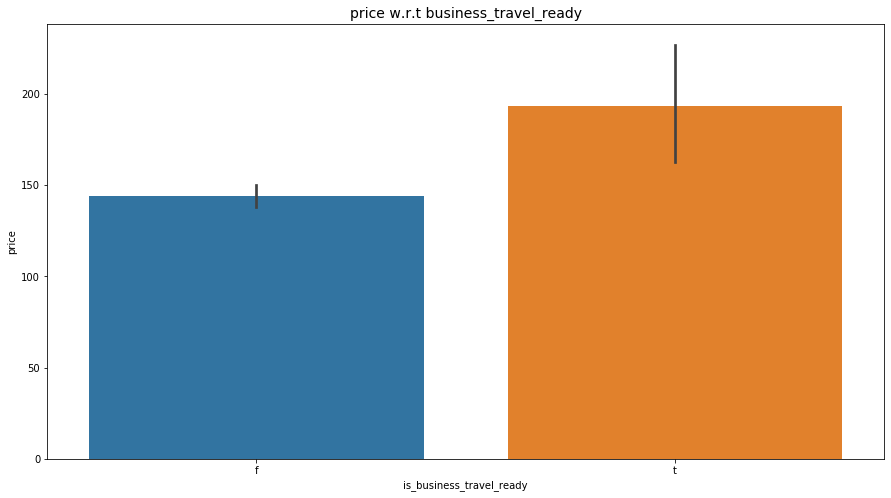

In [95]:
plt.figure(figsize=(15,8))
sns.barplot(x='is_business_travel_ready', y='price', data=air_df)
plt.title('price w.r.t business_travel_ready',fontsize=14)
plt.show()

from the above graph we can infer that the price for business purpose stay is higher.

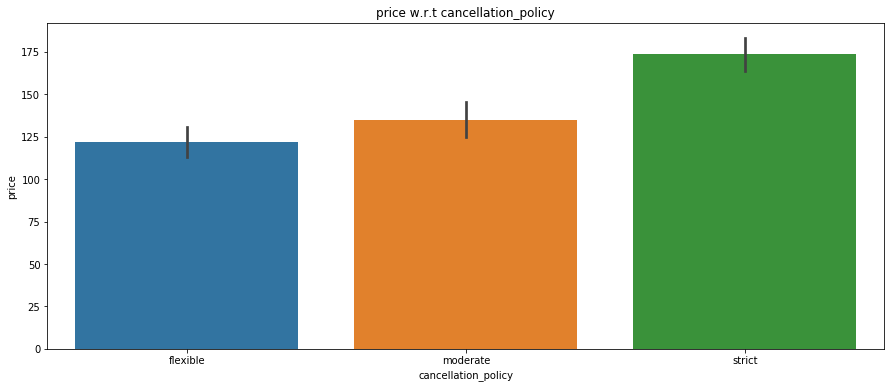

In [98]:
plt.figure(figsize=(15,6))
sns.barplot(air_df['cancellation_policy'],air_df['price'])
plt.title('price w.r.t cancellation_policy')
plt.show()

In [ ]:
# make use of a bar plot

from the above plot we can learn that the price range increase as the cancellation policy moves form flexible to strict

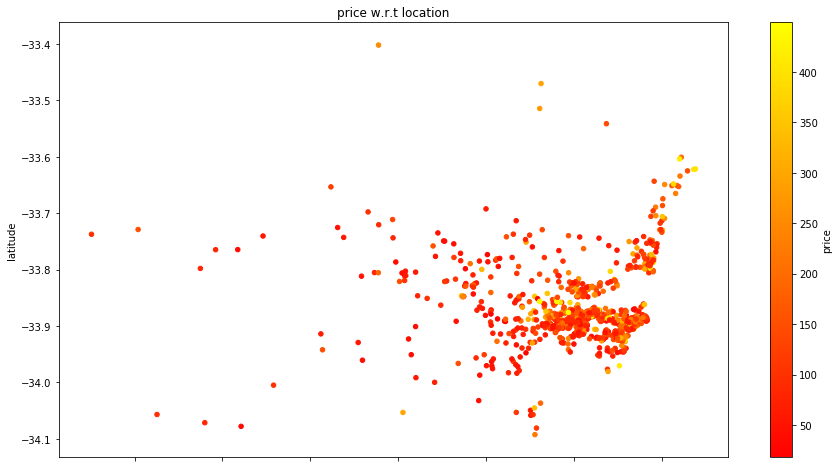

In [99]:
air_df.plot(kind='scatter',x='longitude',y='latitude', c='price',figsize=(15,8), colorbar=True, alpha=1, cmap='autumn')
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.title('price w.r.t location')
plt.show()

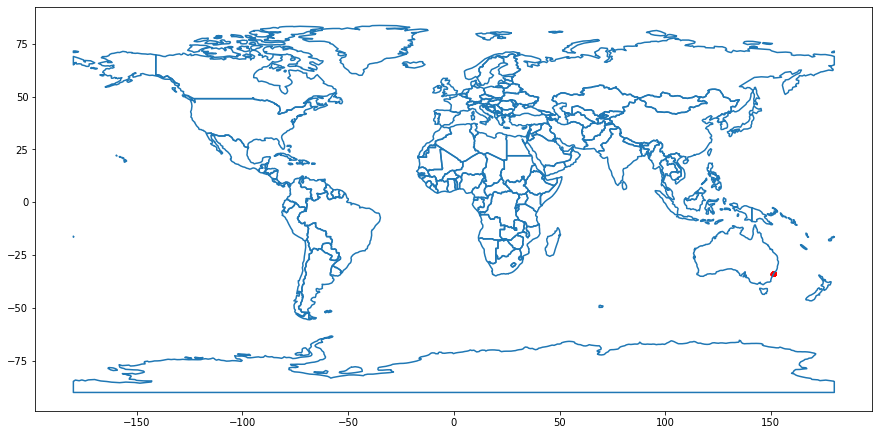

In [113]:
from shapely.geometry import Point
import geopandas as gpd
from geopandas import GeoDataFrame

geometry = [Point(xy) for xy in zip(air_df['longitude'], air_df['latitude'])]
gdf = GeoDataFrame(air_df, geometry=geometry)   

world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
gdf.plot(ax=world.boundary.plot(figsize=(15, 9)), marker='o', color='red', markersize=10)

### Feature -Engineering

    First lets sort categorical variable property_type 

In [114]:
air_df['property_type'].value_counts()

Apartment          651
House              254
Townhouse           32
Other               11
Bed & Breakfast      9
Guesthouse           8
Condominium          7
Cabin                6
Villa                6
Loft                 3
Vacation home        2
Guest suite          2
Bungalow             2
Boat                 2
In-law               1
Hostel               1
Dorm                 1
Boutique hotel       1
Timeshare            1
Name: property_type, dtype: int64

In [115]:
n=air_df['property_type'].value_counts().index[:2]        
air_df['property_type']=air_df.property_type.where(air_df.property_type.isin(n),'other')
air_df['property_type'].value_counts()

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:2: FutureWarning: Implicitly converting categorical to object-dtype ndarray. One or more of the values in 'other' are not present in this categorical's categories. A future version of pandas will raise a ValueError when 'other' contains different categories.

To preserve the current behavior, add the new categories to the categorical before calling 'where', or convert the categorical to a different dtype.
  


Apartment    651
House        254
other         95
Name: property_type, dtype: int64

In [117]:
air_df.isnull().sum()

Id                             0
price                          0
host_is_superhost              0
host_total_listings_count      0
host_identity_verified         0
latitude                       0
longitude                      0
property_type                  0
room_type                      0
accommodates                   0
bathrooms                      0
bedrooms                       0
beds                           0
security_deposit               0
cleaning_fee                   0
extra_people                   0
minimum_nights                 0
maximum_nights                 0
number_of_reviews              0
review_scores_rating           0
review_scores_accuracy         0
review_scores_cleanliness      0
review_scores_checkin          0
review_scores_communication    0
review_scores_location         0
review_scores_value            0
instant_bookable               0
is_business_travel_ready       0
cancellation_policy            0
reviews_per_month              0
geometry  

In [118]:
numeric_col=[]
for col in air_df.select_dtypes(('float64', 'int64')): 
    numeric_col.append(col)

In [121]:
numeric_col.remove('latitude')
numeric_col.remove('longitude')
numeric_col

['Id',
 'price',
 'host_total_listings_count',
 'security_deposit',
 'cleaning_fee',
 'review_scores_rating',
 'review_scores_accuracy',
 'review_scores_cleanliness',
 'review_scores_checkin',
 'review_scores_communication',
 'review_scores_location',
 'review_scores_value',
 'reviews_per_month']

In [122]:
numeric=air_df.loc[:,numeric_col]
nums=np.round(MinMaxScaler().fit_transform(numeric),2)
numeric=pd.DataFrame(nums,columns=numeric_col)
numeric.shape

(1000, 13)

In [124]:
le=LabelEncoder()
cat_col=[]
for col in air_df.select_dtypes('category'):    
    cat_col.append(col)

cat=air_df.loc[:,cat_col]
for col in cat.columns:
    cat[col]=le.fit_transform(cat[col].astype('str'))

cat.shape

(1000, 14)

In [125]:
Air_Df=pd.concat([numeric,cat], axis=1)
Air_Df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 27 columns):
Id                             1000 non-null float64
price                          1000 non-null float64
host_total_listings_count      1000 non-null float64
security_deposit               1000 non-null float64
cleaning_fee                   1000 non-null float64
review_scores_rating           1000 non-null float64
review_scores_accuracy         1000 non-null float64
review_scores_cleanliness      1000 non-null float64
review_scores_checkin          1000 non-null float64
review_scores_communication    1000 non-null float64
review_scores_location         1000 non-null float64
review_scores_value            1000 non-null float64
reviews_per_month              1000 non-null float64
host_is_superhost              1000 non-null int64
host_identity_verified         1000 non-null int64
room_type                      1000 non-null int64
accommodates                   1000 non-null int64
b

### Modeling 

    Now lets split the data set into train and test. You must already have understood why we perform this step, however is this enough?
---

    Usually the data is split into 3 sets: train, validation and test

In [127]:
x=Air_Df.drop('price',axis=1)
y=Air_Df['price']                        

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2, random_state=1)

In [128]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 26)
(200, 26)
(800,)
(200,)


#### Linear Regression

In [153]:
rmse_linear_regression = LinearRegression()
rmse_linear_regression.fit(x_train,y_train)
pred = rmse_linear_regression.predict(x_test)
rmse = metrics.mean_squared_error(y_test,pred)
print('Linear Regression RMSE: ',math.sqrt(rmse))

Linear Regression RMSE:  0.15175678498289386


In [154]:
r_sq=metrics.r2_score(y_test,pred)
print('R_squared:',r_sq)

R_squared: 0.5078192208327017


    The RMSE is certainly good but the R_squared isn't quite so

#### DecisionTree

In [155]:
dt = DecisionTreeRegressor(max_depth=10,min_samples_leaf=3)
dt.fit(x_train,y_train)
pred = dt.predict(x_test)
rmse = metrics.mean_squared_error(y_test,pred)
print('Decision Tree RMSE: ',math.sqrt(rmse))

Decision Tree RMSE:  0.18253029450863853


In [156]:
r_sq=metrics.r2_score(y_test,pred)
print('R_squared:',r_sq)

R_squared: 0.2879699479935577


    The R squared reduced from existing 50% to 28%. Turns out Decision tree performed worse than Linear Regression

#### RandomForest

In [157]:
rand = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_depth=20)
rand.fit(x_train,y_train)
pred=rand.predict(x_test)
rmse = metrics.mean_squared_error(y_test,pred)
print('RandomForest RMSE: ',math.sqrt(rmse))

RandomForest RMSE:  0.15024398110050205


In [158]:
r_sq=metrics.r2_score(y_test,pred)
print('R_squared:',r_sq)

R_squared: 0.517583025667412


#### Ridge Regression

In [160]:
ridge = RidgeCV()
ridge.fit(x_train,y_train)
pred = ridge.predict(x_test)
rmse = metrics.mean_squared_error(y_test,pred)
print('Ridge regression RMSE: ',math.sqrt(rmse))

Ridge regression RMSE:  0.15226211638681586


In [161]:
r_sq=metrics.r2_score(y_test,pred)
print('R_squared:',r_sq)

R_squared: 0.504535960735759


#### Lasso Regression

In [162]:
lasso = LassoCV()
lasso.fit(x_train,y_train)
pred = lasso.predict(x_test)
rmse = metrics.mean_squared_error(y_test,pred)
print('Lasso regression RMSE: ',math.sqrt(rmse))

Lasso regression RMSE:  0.15427623821061676


In [163]:
r_sq=metrics.r2_score(y_test,pred)
print('R_squared:',r_sq)

R_squared: 0.49134127739644007


    We have seen how the most common regression models performed with our data. The next step is to tune the hyperparameters to identify the best parameters to improve the model performance. Go ahead and tune the hyperparameters.
    Before you leave, let's just check the feature importances as per our RandomForest model

In [164]:
importance=rand.feature_importances_

In [165]:
feature_imp=pd.DataFrame({'columns':x_test.columns,'importances':np.round(importance,2)})
feature_imp.sort_values(by='importances', ascending=False)

,columns,importances
14,room_type,0.43
17,bedrooms,0.13
15,accommodates,0.10
0,Id,0.04
3,cleaning_fee,0.04
2,security_deposit,0.03
18,beds,0.03
16,bathrooms,0.03
22,number_of_reviews,0.02
20,minimum_nights,0.02


    The bottom 5-10 features played pretty much no role in predicting the price. However, room_type is the most important and removal of all other features could still lead to a decent score with only room_type.
    Now that we had a look at how features are contributing, why don't you use all the findings from this notebook and apply them on your own implementation